In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.signal import stft

In [46]:
# Load the data
magnitude_data = loadmat(r'Zakir_sitting\P01A\P0A1\Amplitude.mat')["Data_amplitude"]  
phase_data = loadmat(r'\Zakir_sitting\P01A\P0A1\Phase.mat')["Data_phase"]
IQ_data = loadmat(r"Zakir_sitting\P01A\P0A1\IQ_data")['Data_IQ']

In [47]:
# Check the number of range bins
num_range_bins = magnitude_data.shape[0]
print(f"The number of range bins is: {num_range_bins}")

The number of range bins is: 3247


In [48]:
def stft_analysis(data):
    # Computing the STFT over the time axis, which is axis 1
    f, t, Zxx = stft(data, axis=1, nperseg=128, noverlap=64)
    magnitude_spectrum = np.abs(Zxx)
    
    # Averaging over frequency bins
    avg_magnitude_spectrum = np.mean(magnitude_spectrum, axis=0)

    # Using imshow for visualization
    plt.imshow(np.log1p(avg_magnitude_spectrum.T), aspect='auto', origin='lower', cmap='jet', extent=[t[0], t[-1], 0, data.shape[0]])
    
    plt.title('STFT Magnitude Spectrum (averaged over frequency bins)')
    plt.ylabel('Range Bins')
    plt.xlabel('Time (s)')
    plt.colorbar()
    plt.show()

def range_bin_statistics(data):
    mean_values = np.mean(data, axis=1)
    std_values = np.std(data, axis=1)
    range_bins = np.arange(data.shape[0])
    
    plt.plot(range_bins, mean_values, label='Mean')
    plt.fill_between(range_bins, mean_values-std_values, mean_values+std_values, alpha=0.2)
    plt.title('Range Bin Statistics')
    plt.xlabel('Range Bin')
    plt.ylabel('Value')
    plt.legend()
    plt.show()
    
def iq_scatter(iq_data):
    plt.scatter(iq_data[:, 0], iq_data[:, 1], s=5)
    plt.title("IQ Scatter Plot")
    plt.xlabel('I')
    plt.ylabel('Q')
    plt.show()


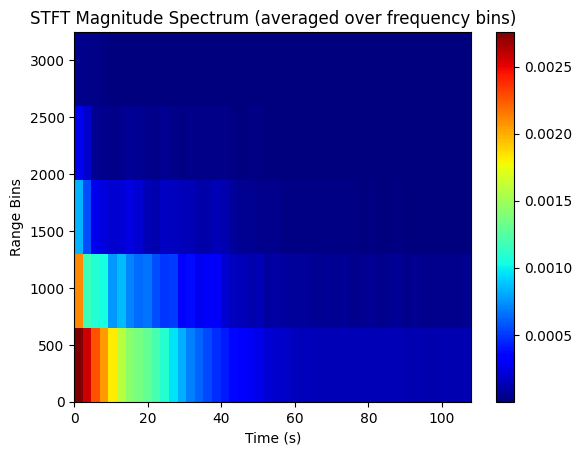

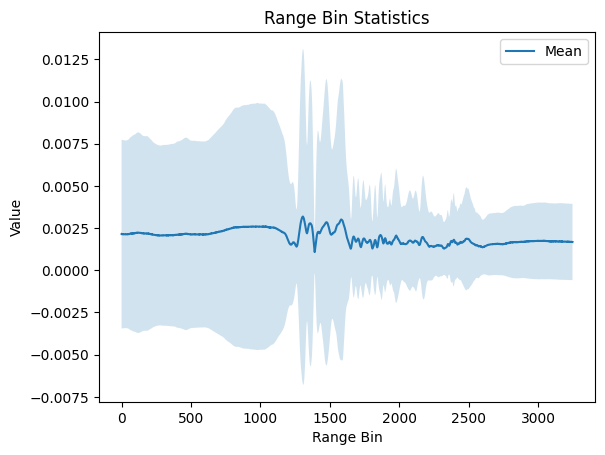

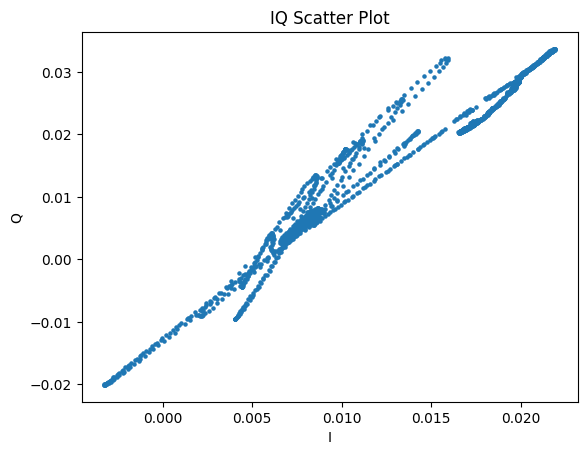

In [49]:
# Visualize the data
stft_analysis(magnitude_data)
range_bin_statistics(magnitude_data)
iq_scatter(IQ_data)

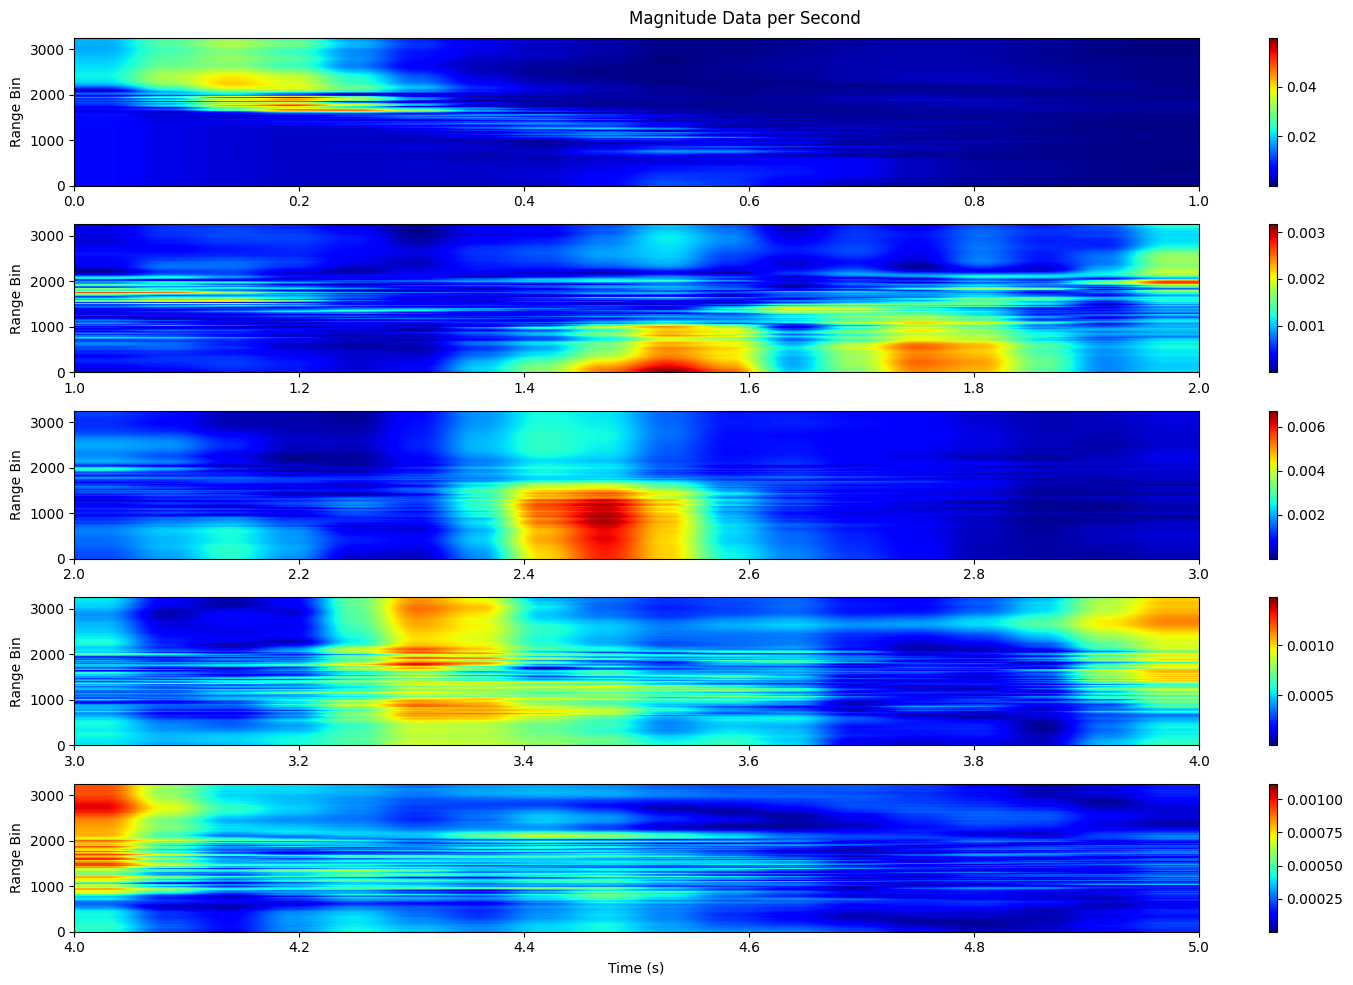

In [50]:
# Assuming you have equal time samples for each second
samples_per_second = magnitude_data.shape[1] // 5

# Visualization function
def plot_per_second(data, title):
    plt.figure(figsize=(15, 10))
    for i in range(5):
        segment = data[:, i*samples_per_second:(i+1)*samples_per_second]
        plt.subplot(5, 1, i+1)
        plt.imshow(segment, aspect='auto', cmap='jet', extent=[i, i+1, 0, 3247])
        plt.colorbar()
        plt.ylabel('Range Bin')
        if i == 4:
            plt.xlabel('Time (s)')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

# Visualize the magnitude data for each second
plot_per_second(magnitude_data, 'Magnitude Data per Second')


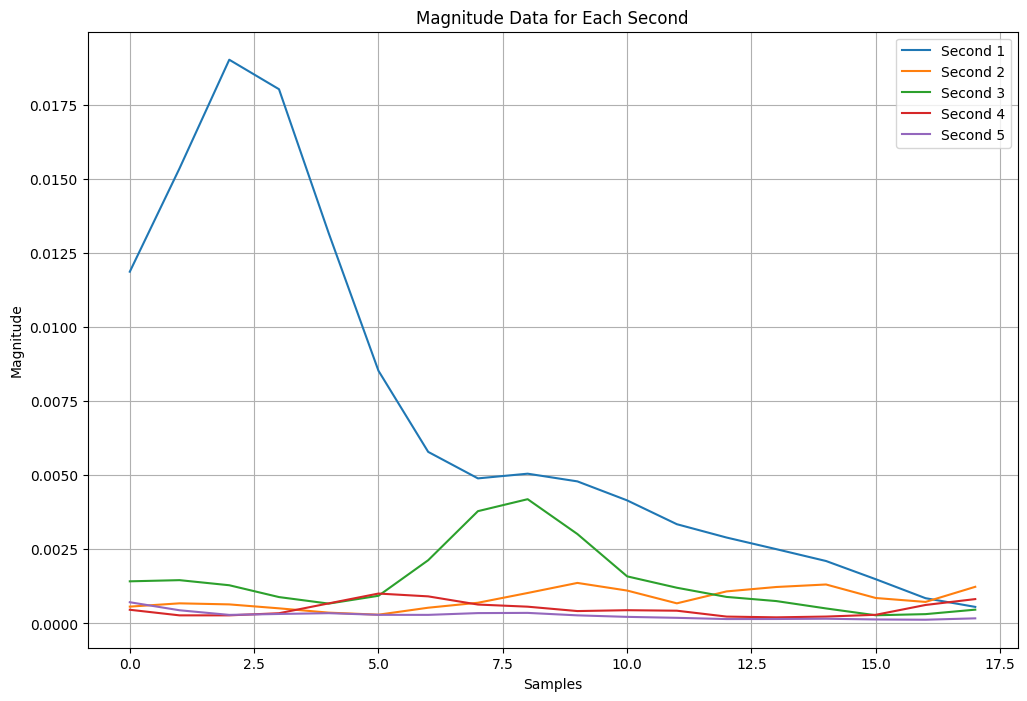

In [41]:
# Determine how many samples correspond to 1 second
samples_per_second = magnitude_data.shape[1] // 5

# Plotting
plt.figure(figsize=(12, 8))
for i in range(5):
    segment = magnitude_data[:, i*samples_per_second:(i+1)*samples_per_second]
    aggregated_segment = np.mean(segment, axis=0)  # Average over range bins
    plt.plot(aggregated_segment, label=f'Second {i+1}')

plt.title('Magnitude Data for Each Second')
plt.xlabel('Samples')
plt.ylabel('Magnitude')
plt.legend()
plt.grid(True)
plt.show()


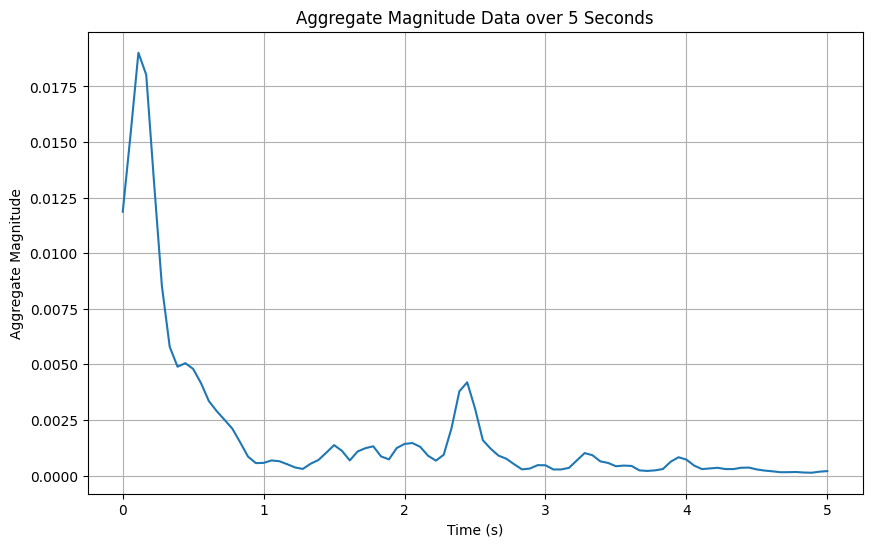

In [39]:
# Aggregate data across range bins
aggregate_data = np.mean(magnitude_data, axis=0)  # Here, we use mean. You can replace with np.sum() if desired.

# Plotting
plt.figure(figsize=(10, 6))
plt.plot(np.linspace(0, 5, len(aggregate_data)), aggregate_data)
plt.title('Aggregate Magnitude Data over 5 Seconds')
plt.xlabel('Time (s)')
plt.ylabel('Aggregate Magnitude')
plt.grid(True)
plt.show()
